# Finite volumes: cell averages and fluxes

Until now we stored samples of $u$ at points. Here we store averages over cells and we work at the interfaces between them.

### Notation

$$x \to i\,, \qquad t \to n,$$

but now $i$ labels a **cell**, not a point, and the unknown is the average over that cell,

$$\langle u \rangle_i = \frac{1}{\Delta x} \int_{x_{i-1/2}}^{x_{i+1/2}} u(x)\,dx,$$

which we store as `u[i]`. The interfaces carry half indices.

The flux at an interface comes in three flavours: $F(u)$ is the physical flux of the conservation law, $\bar{F}_{i+1/2}$ is its exact average over one step, and $\hat{F}(u_L, u_R)$ is the numerical flux, the two-argument function the code actually computes.


### The update in flux form:

$$\langle u \rangle_i^{\,n+1} = \langle u \rangle_i^{\,n} - \frac{\Delta t}{\Delta x} \left( \hat{F}_{i+1/2} - \hat{F}_{i-1/2} \right)$$

Each interface flux is used twice, once by the cell on its left and once by the cell on its right, with opposite signs. That is the whole reason the total is conserved.

**Reference**: M. Zingale, *Introduction to Computational Astrophysical Hydrodynamics*, Chapter 3 and Section 5.1.

## Set-up: libraries and the domain

In [22]:
# Import libraries

import numpy as np

import matplotlib.pyplot as plt

### 1. Domain definition (grid creation):

The domain is $0 \le x \le 2\pi$, as in nb09, and it is cut into `ni` cells
of width $\Delta x$. The cell centres sit at

$$x_i = x_{\min} + \left( i + \tfrac{1}{2} \right)\Delta x,$$

so no cell centre lands on a boundary.

In [23]:
# Limits for the spatial vector
x_min = 0.
x_max = 2.*np.pi

def make_grid(ni_num):

    dx_num = (x_max - x_min)/ni_num

    # Cell centres, offset by half a cell
    x_vec = x_min + (np.arange(ni_num) + 0.5)*dx_num

    return x_vec, dx_num


In [24]:
# Grid used in Part I
ni = 40

x, dx = make_grid(ni)

print(f"ni = {ni},  dx = {dx:.5f}, first centre = {x[0]:.5f}, last centre = {x[-1]:.5f}")

ni = 40,  dx = 0.15708, first centre = 0.07854, last centre = 6.20465


# Part I. The cell average

### 1. The average against the value at the centre:

A Taylor expansion about the centre of the cell gives

$$\langle u \rangle_i = u(x_i) + \frac{\Delta x^2}{24}\,\frac{\partial^2 u}{\partial x^2}\bigg|_{x_i} + \mathcal{O}(\Delta x^4)$$

We check it on $u = \sin x$, whose cell average we can write down exactly:

$$\langle u \rangle_i = \frac{1}{\Delta x} \int_{x_i - \Delta x/2}^{x_i + \Delta x/2} \sin x\, dx = \frac{\cos(x_i - \Delta x/2) - \cos(x_i + \Delta x/2)}{\Delta x}$$

In [25]:
def cell_average_sin(x_vec, dx_num):

    c_av = (np.cos(x_vec - 0.5*dx_num) - np.cos(x_vec + 0.5*dx_num))/dx_num

    return c_av

In [26]:
print(f"{'ni':>6s} {'max error':>13s} {'rate':>7s} {'dx^2/24 |u_xx|':>16s}")

err_old = None

for ni_num in (20, 40, 80, 160, 320, 640):

    x_vec, dx_num = make_grid(ni_num)

    # The exact average minus the value at the centre
    err = np.max(np.abs(cell_average_sin(x_vec, dx_num) - np.sin(x_vec)))

    # Taylor term prediction, since u_xx = -sin x
    pred = dx_num**2/24.*np.max(np.abs(np.sin(x_vec)))

    rate = "" if err_old is None else f"{np.log2(err_old/err):7.2f}"

    print(f"{ni_num:6d} {err:13.4e} {rate:>7s} {pred:16.4e}")

    err_old = err

    ni     max error    rate   dx^2/24 |u_xx|
    20    4.0567e-03               4.0617e-03
    40    1.0246e-03    1.99       1.0249e-03
    80    2.5680e-04    2.00       2.5682e-04
   160    6.4242e-05    2.00       6.4243e-05
   320    1.6063e-05    2.00       1.6063e-05
   640    4.0159e-06    2.00       4.0159e-06


#### Observations:

- Note that the measured error sits on the predicted value to four digits and falls by a factor of four each time the mesh is halved. 

- The average and the centre value agree to second order, which is why the FD schemes of previous lectures never had to indicate which of the two they were storing.

### 2. Ghost Cells and Boundary Conditions:

A finite-volume update needs the two neighbours of every cell, including the cells at the ends of the domain. We add `ng` cells outside each end and fill them before every step, so that the update formula itself has no special case.


### Types of boundary conditions:

- **periodic**: copy from the far end.

- **outflow**: copy the first interior cell, which makes the gradient zero.

- **reflecting**: mirror the interior cells about the boundary.

In [27]:
def add_ghost(u_vec, bc = "periodic", ng = 1):

    # All points: interior + ghost cells
    u_ext = np.empty(len(u_vec) + 2*ng)

    # Interior points
    u_ext[ng:-ng] = u_vec

    if bc == "periodic":
        u_ext[:ng] = u_vec[-ng:]
        u_ext[-ng:] = u_vec[:ng]

    elif bc == "outflow":
        u_ext[:ng] = u_vec[0]
        u_ext[-ng:] = u_vec[-1]

    elif bc == "reflecting":
        u_ext[:ng] = u_vec[ng-1::-1]
        u_ext[-ng:] = u_vec[-1:-ng-1:-1]

    return u_ext

In [28]:
# Test vector to see all 3 cases
u_test = np.array([1., 2., 3., 4., 5.])

print("original          ", u_test)
for bc in ("periodic", "outflow", "reflecting"):
    print(f"{bc:12s} {add_ghost(u_test, bc, ng = 2)}")

original           [1. 2. 3. 4. 5.]
periodic     [4. 5. 1. 2. 3. 4. 5. 1. 2.]
outflow      [1. 1. 1. 2. 3. 4. 5. 5. 5.]
reflecting   [2. 1. 1. 2. 3. 4. 5. 5. 4.]


# Part II. The Burgers shock as a flux update

Here we consider the same problem as nb09: 

$$\frac{\partial u}{\partial t} + \frac{\partial F}{\partial x} = 0$$


with $F = \frac{u^2}{2}$. This is the inviscid equation from a square pulse with $u = 2$ inside and $u = 1$ outside.

Recall that the Rankine-Hugoniot speed is $s = (u_1 + u_2)/2 = 1.5$.

In nb09 we differenced the solution; here we build one flux per interface and then subtract.

### 1. Set up ICs/BCs:

In [29]:
# The two states
u_hi = 2.
u_lo = 1.

# Edges of the pulse at t = 0
xa = 1.
xb = 3.

# Exact shock speed, Rankine-Hugoniot
s_exact = 0.5*(u_hi + u_lo)


def square_pulse(x_vec, x_left = xa, x_right = xb):

    u_vec = np.full_like(x_vec, u_lo)
    u_vec[(x_vec >= x_left) & (x_vec <= x_right)] = u_hi

    return u_vec


print(f"exact shock speed = {s_exact}")

exact shock speed = 1.5


### 2. The flux function:

While $u > 0$ everywhere, the information comes from the left, so the interface takes the flux of the cell on its left:

$$\hat{F}_{i+1/2} = \frac{u_L^2}{2}$$

This is the same choice we made in `nb09`, written as a flux.

In [30]:
def flux_upwind(u_left, u_right):

    # Valid while u > 0, the information comes from the left
    f_l = 0.5*u_left**2
    
    return f_l

### 3. Time marching:

One step reads the ghost-filled array, builds `ni + 1` interface fluxes and subtracts consecutive pairs.

We keep the non-conservative form of nb09 for comparison: it has no flux, so nothing cancels.

In [31]:
def march_fv(ics_vec, dx_num, dt_num, n_steps, form = "conservative",
             flux = flux_upwind):

    u_vec = ics_vec.copy()

    # The total at every level, to be tracked
    total = [u_vec.sum()*dx_num]

    # time loop (index n)
    for n in range(n_steps):

        u_ext = add_ghost(u_vec, "periodic")

        if form == "conservative":

            # One flux per interface: ni + 1 of them
            f_face = flux(u_ext[:-1], u_ext[1:])

            u_vec = u_vec - dt_num/dx_num*(f_face[1:] - f_face[:-1])

        else:

            u_vec = (u_vec - u_vec*dt_num/dx_num*(u_ext[1:-1] - u_ext[:-2]))

        total.append(u_vec.sum()*dx_num)

    return u_vec, np.array(total)

### 4. Running both forms on the same grid:

In [32]:
# Grid for the shock test
ni_s = 1000

x_s, dx_s = make_grid(ni_s)

# Courant number based on the largest speed
cfl = 0.4

# Time step from CFL
dt_s = cfl*dx_s/u_hi

# March to t = 1
t_end = 1.
n_steps = int(round(t_end/dt_s))
dt_s = t_end/n_steps

# Add IC
ics_s = square_pulse(x_s)

u_cons, tot_cons = march_fv(ics_s, dx_s, dt_s, n_steps)
u_prim, tot_prim = march_fv(ics_s, dx_s, dt_s, n_steps, form = "non-conservative")

### 5. Comparison of both approaches at $t_{\rm final}$:

The telescoping sum says that on a periodic domain the conservative form cannot change (to round-off) the total at all.

In [33]:
def exact_pulse(x_vec, t_num):

    u_vec = np.full_like(x_vec, u_lo)

    fan_lo = xa + u_lo*t_num
    fan_hi = xa + u_hi*t_num
    shock = xb + s_exact*t_num

    # the plateau -> wedge
    u_vec[(x_vec >= fan_hi) & (x_vec < shock)] = u_hi

    # the fan
    fan = (x_vec >= fan_lo) & (x_vec < fan_hi)

    if t_num > 0.:
        u_vec[fan] = (x_vec[fan] - xa)/t_num

    return u_vec

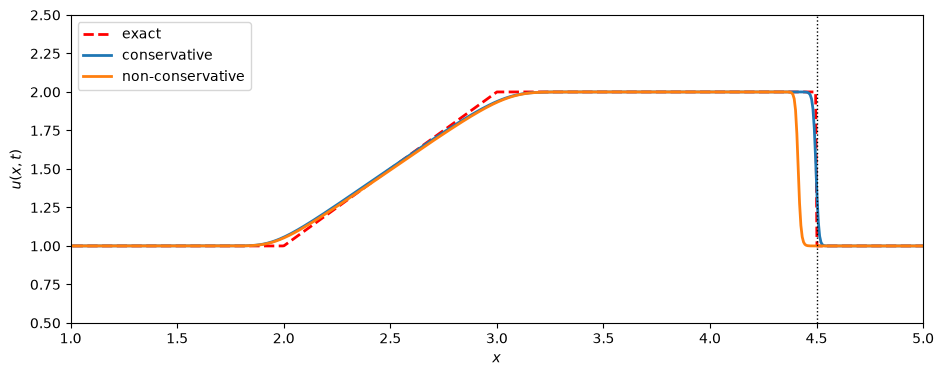

In [34]:
plt.figure(figsize=(11,4))

plt.plot(x_s, exact_pulse(x_s, t_end), color = "red", ls = "--", lw = 2,
         label = "exact")
plt.plot(x_s, u_cons, lw = 2, label = "conservative")
plt.plot(x_s, u_prim, lw = 2, label = "non-conservative")

plt.axvline(xb + s_exact*t_end, color = "k", lw = 1, ls = ":")

plt.xlabel(r"$x$")
plt.ylabel(r"$u(x,t)$")

plt.xlim(1., 5.)
plt.ylim(0.5, 2.5)

plt.legend()

plt.show()

# Part III. Choosing the flux

`flux_upwind` always reads the cell on the left. That is the right side to read only while $u > 0$.

A flux function has to work whichever way the information travels. The Rusanov flux does it by adding a diffusion scaled by the largest local wave speed:

$$\hat{F}(u_L, u_R) = \frac{1}{2}\left[ F(u_L) + F(u_R) \right] - \frac{\alpha}{2}\left( u_R - u_L \right), \qquad \alpha = \max\left( |u_L|, |u_R| \right)$$

When the two sides agree the second term vanishes and the first one is $F(u)$, so the flux is consistent.

### 1. The Rusanov flux:

In [35]:
def flux_rusanov(u_left, u_right):

    # The largest wave speed at the interface, since F'(u) = u
    alpha = np.maximum(np.abs(u_left), np.abs(u_right))

    return (0.25*(u_left**2 + u_right**2) - 0.5*alpha*(u_right - u_left))

### 2. The Rusanov flux on the shock problem:

It is a flux function too, so it conserves as well. On the square pulse the
one-sided formula was already reading the correct side, so the two should
agree on the speed and differ only in how wide the front is.

In [36]:
# The same shock problem, now with the Rusanov flux
u_rus, tot_rus = march_fv(ics_s, dx_s, dt_s, n_steps, flux = flux_rusanov)

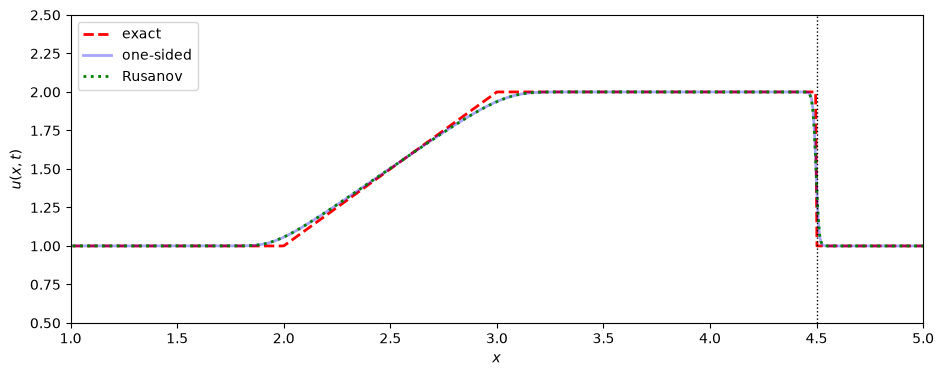

In [37]:
plt.figure(figsize=(11,4))

plt.plot(x_s, exact_pulse(x_s, t_end), color = "red", ls = "--", lw = 2, label = "exact")

plt.plot(x_s, u_cons, color = "blue", lw = 2, alpha = 0.35, label = "one-sided")
plt.plot(x_s, u_rus, color = "green", linestyle = ":", lw = 2, label = "Rusanov")

plt.axvline(xb + s_exact*t_end, color = "k", lw = 1, ls = ":")

plt.xlabel(r"$x$")
plt.ylabel(r"$u(x,t)$")

plt.xlim(1., 5.)
plt.ylim(0.5, 2.5)

plt.legend()

plt.show()

### 3. The same shock, with the sign of $u$ reversed:

Now we mirror the pulse: $u = -2$ on $3 \le x \le 5$ and $u = -1$ outside. Same equation, same jump, same grid. The only change is that $u$ is
negative everywhere, so at every interface the information now arrives from the right.

- `flux_upwind` still reads the cell on the left, which is now the wrong side at every single interface, and no choice of time step repairs that.

- The Rusanov flux has no preferred side, so it carries the mirrored shock at the Rankine-Hugoniot speed $s = -1.5$.

In [38]:
# The pulse of Part II, mirrored: u = -2 on 3 <= x <= 5, u = -1 outside
ics_neg = -square_pulse(6. - x_s)

# A few steps is all it takes to tell the two fluxes apart
n_few = 4

u_neg_one, _ = march_fv(ics_neg, dx_s, dt_s, n_few, flux = flux_upwind)
u_neg_rus, _ = march_fv(ics_neg, dx_s, dt_s, n_few, flux = flux_rusanov)

# The full march to t_end, which only one of the two survives
u_full_rus, tot_neg = march_fv(ics_neg, dx_s, dt_s, n_steps, flux = flux_rusanov)

t_few = n_few*dt_s


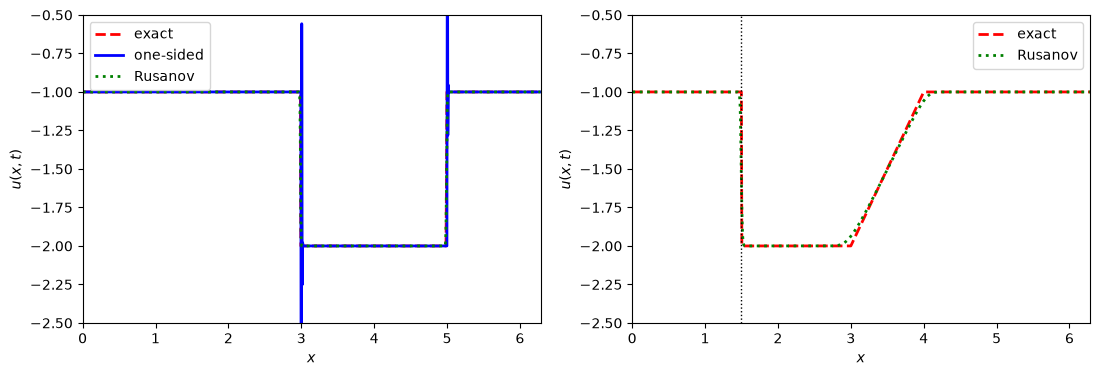

In [39]:
fig, ax = plt.subplots(1, 2, figsize = (13,4))

ax[0].plot(x_s, -exact_pulse(6. - x_s, t_few), color = "red", ls = "--", lw = 2, label = "exact")
ax[0].plot(x_s, u_neg_one, color = "blue", lw = 2, label = "one-sided")
ax[0].plot(x_s, u_neg_rus, color = "green", ls = ":", lw = 2, label = "Rusanov")
ax[0].set_ylim(-2.5, -0.5)

ax[1].plot(x_s, -exact_pulse(6. - x_s, t_end), color = "red", ls = "--", lw = 2, label = "exact")
ax[1].plot(x_s, u_full_rus, color = "green", ls = ":", lw = 2, label = "Rusanov")
ax[1].axvline(3. - s_exact*t_end, color = "k", lw = 1, ls = ":")
ax[1].set_ylim(-2.5, -0.5)

for a_i in ax:
    a_i.set_xlabel(r"$x$")
    a_i.set_ylabel(r"$u(x,t)$")
    a_i.set_xlim(x_min, x_max)
    a_i.legend()

plt.show()

### 4. An initial condition that changes sign:

We take $u = \sin x$ on the same periodic domain. The shock forms at
$x = \pi$ at $t = 1$, and $u < 0$ over half the domain throughout.

In [40]:
def march_sign(ni_num, flux, t_final = 1., cfl_num = 0.4):

    x_vec, dx_num = make_grid(ni_num)

    u_vec = np.sin(x_vec)

    peaks = [np.abs(u_vec).max()]

    t_num = 0.

    while t_num < t_final - 1.e-14:

        # The speed changes as the solution steepens, so dt is recomputed
        dt_num = min(cfl_num*dx_num/np.abs(u_vec).max(), t_final - t_num)

        u_ext = add_ghost(u_vec, "periodic")

        f_face = flux(u_ext[:-1], u_ext[1:])

        u_vec = u_vec - dt_num/dx_num*(f_face[1:] - f_face[:-1])

        t_num = t_num + dt_num

        peaks.append(np.abs(u_vec).max())

        if not np.isfinite(u_vec).all() or peaks[-1] > 1.e6:
            break

    return x_vec, u_vec, np.array(peaks)

### 5. Time marching:

In [41]:
# Time marching
x_r, u_r, peaks_r = march_sign(400, flux_rusanov)
x_n, u_n, peaks_n = march_sign(400, flux_upwind)

# The one-sided march before it runs away, so it can be drawn below
x_e, u_e, peaks_e = march_sign(400, flux_upwind, t_final = 0.3)


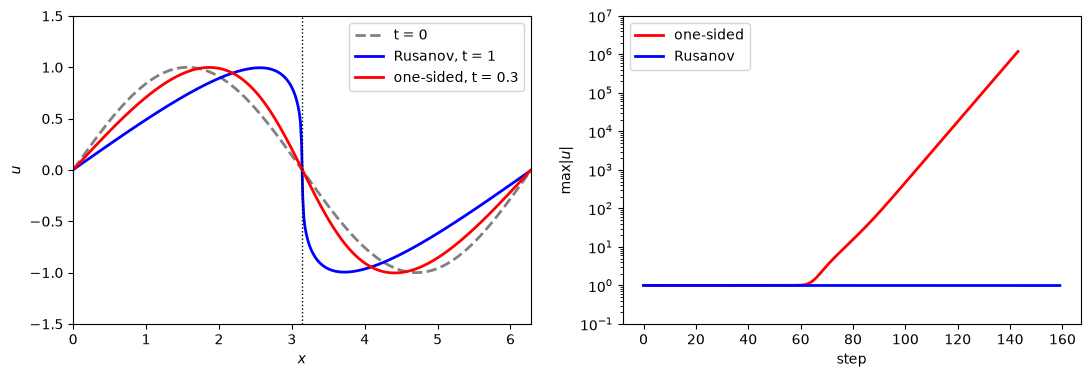

In [42]:
fig, ax = plt.subplots(1, 2, figsize = (13,4))

ax[0].plot(x_r, np.sin(x_r), color = "0.5", ls = "--", lw = 2, label = "t = 0")
ax[0].plot(x_r, u_r, color = "blue", lw = 2, label = "Rusanov, t = 1")

# the one-sided solution has diverged by t = 1, so it is drawn at t = 0.3
ax[0].plot(x_e, u_e, color = "red", lw = 2, label = "one-sided, t = 0.3")

ax[0].axvline(np.pi, color = "k", lw = 1, ls = ":")
ax[0].set_ylim(-1.5, 1.5)
ax[0].set_xlabel(r"$x$")
ax[0].set_ylabel(r"$u$")
ax[0].set_xlim(x_min, x_max)
ax[0].legend()

ax[1].semilogy(np.arange(len(peaks_n)), np.maximum(peaks_n, 1.e-3), color = "red", lw = 2, label = "one-sided")
ax[1].semilogy(np.arange(len(peaks_r)), peaks_r, color = "blue", lw = 2, label = "Rusanov")
ax[1].set_xlabel("step")
ax[1].set_ylabel(r"$\max |u|$")
ax[1].set_ylim(1.e-1, 1.e7)
ax[1].legend()

plt.show()

### Observations:

- The correctness of `flux_upwind` is bound to the sign of $u$. On $u = \sin x$ it reads the wrong side over half the domain and the march diverges within about sixty steps.

- With the sign of $u$ reversed the one-sided formula fails. Within a few steps it has left the range of the data. Rusanov carries the mirrored shock at the Rankine-Hugoniot speed $-1.5$ till the end.

- The flux function should decide which side the information comes from!